> **Benchmark v2 (21 Nov 2026).** The cells below this note are the original **v1** work, kept for history. Their split is not patient-grouped (or uses the test fold for early stopping or the threshold), so their numbers are optimistic. The official evaluation is the section **v2: patient-grouped 3-fold** at the end of this notebook. Run it from `.venv`.

In [1]:
# Decision tree benchmark: 3-fold evaluation on heart-sound features
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from mlflow.models import infer_signature
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

PROJECT_ROOT = next((candidate for candidate in (Path.cwd(), *Path.cwd().parents) if (candidate / "features_normal_train.data").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the CardioAgent-Ops project.")
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from benchmark_common import CLASS_NAMES, FEATURE_NAMES, load_heart_sound_features


In [2]:
# The same 22 features used by the SVM: duration, SNR, and 20 Mel-band means.
X, y = load_heart_sound_features(PROJECT_ROOT)
print(f"X: {X.shape}; normal: {(y == 0).sum()}; abnormal: {(y == 1).sum()}")
pd.DataFrame(X, columns=FEATURE_NAMES).head()


X: (3785, 22); normal: 1016; abnormal: 2769


,duration,snr,mel_1,mel_2,mel_3,mel_4,mel_5,mel_6,mel_7,mel_8,...,mel_11,mel_12,mel_13,mel_14,mel_15,mel_16,mel_17,mel_18,mel_19,mel_20
0,8.8075,0.006710,-16.841677,-19.688116,-21.856184,-23.289961,-24.160439,-24.869219,-26.234570,-26.597385,...,-28.332466,-30.052866,-31.126770,-31.872873,-32.015453,-32.058754,-32.296711,-33.377346,-34.338982,-37.693394
1,4.6805,0.026340,-15.626101,-17.922735,-23.287146,-25.556116,-26.411135,-27.813147,-32.265320,-34.176247,...,-36.818405,-39.425304,-41.588394,-42.392761,-43.119179,-42.211365,-40.343189,-43.195286,-42.899567,-45.423008
2,6.2100,-0.005204,-10.242869,-15.327780,-22.351292,-25.240929,-25.592972,-27.282160,-30.807951,-32.663952,...,-37.543346,-38.923923,-40.303925,-41.350079,-42.948063,-43.463230,-44.061802,-46.509251,-47.638233,-51.660030
3,9.9025,-0.000561,-8.903273,-12.322722,-21.110411,-25.281317,-27.352064,-29.352558,-29.425699,-29.711435,...,-37.268936,-39.308430,-40.764217,-42.506432,-43.755527,-44.263844,-43.572689,-46.335548,-47.275906,-51.267986
4,5.1205,-0.005855,-9.271482,-11.864514,-21.290575,-25.446054,-28.036386,-30.982750,-31.445566,-32.264351,...,-37.496056,-39.882446,-42.946991,-44.928062,-47.092705,-48.155983,-47.683861,-51.837048,-53.428150,-57.216736


,fold,accuracy,precision,recall,f1
0,1,0.807,0.883,0.848,0.865
1,2,0.795,0.855,0.866,0.861
2,3,0.787,0.857,0.850,0.854


Mean metrics:


,accuracy,precision,recall,f1
mean,0.796,0.865,0.855,0.86


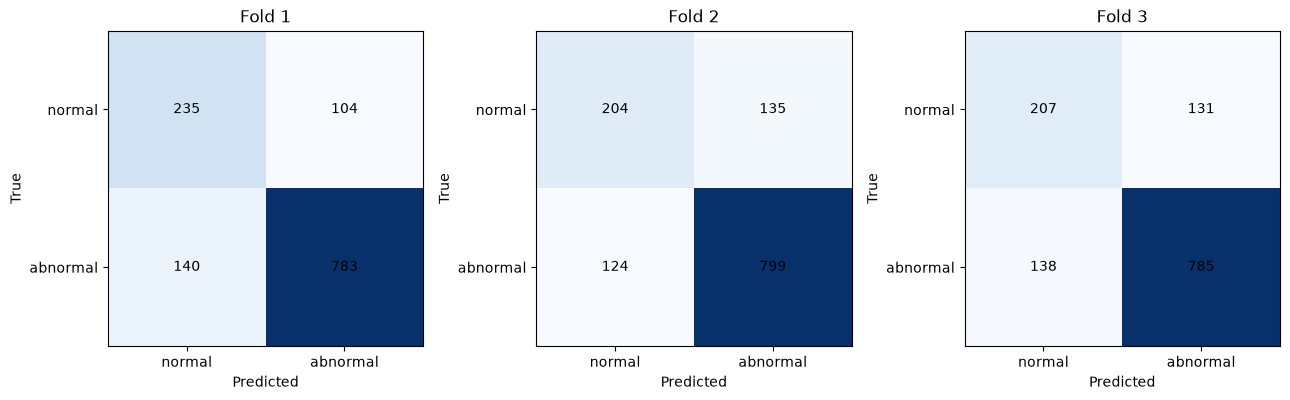

In [3]:
# Three stratified folds keep the normal/abnormal proportion in every test set.
def make_tree():
    return DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=1)

splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
fold_metrics, fold_confusions = [], []
for fold, (train_index, test_index) in enumerate(splitter.split(X, y), start=1):
    tree = make_tree()
    tree.fit(X[train_index], y[train_index])
    predicted = tree.predict(X[test_index])
    metrics = {
        "fold": fold,
        "accuracy": float(accuracy_score(y[test_index], predicted)),
        "precision": float(precision_score(y[test_index], predicted, zero_division=0)),
        "recall": float(recall_score(y[test_index], predicted, zero_division=0)),
        "f1": float(f1_score(y[test_index], predicted, zero_division=0)),
    }
    fold_metrics.append(metrics)
    fold_confusions.append({"fold": fold, "labels": CLASS_NAMES, "matrix": confusion_matrix(y[test_index], predicted, labels=[0, 1]).tolist()})

results = pd.DataFrame(fold_metrics)
display(results.round(3))
print("Mean metrics:")
display(results[["accuracy", "precision", "recall", "f1"]].mean().to_frame("mean").T.round(3))

# Keep a visual version of every fold's confusion matrix for MLflow.
figure, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, item in zip(axes, fold_confusions):
    matrix = np.asarray(item["matrix"])
    axis.imshow(matrix, cmap="Blues")
    axis.set_title(f"Fold {item['fold']}")
    axis.set_xticks([0, 1], CLASS_NAMES)
    axis.set_yticks([0, 1], CLASS_NAMES)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("True")
    for row, column in np.ndindex(matrix.shape):
        axis.text(column, row, str(matrix[row, column]), ha="center", va="center")
figure.tight_layout()
confusion_figure_path = PROJECT_ROOT / "decision_tree_confusion_matrices.png"
figure.savefig(confusion_figure_path, dpi=150)
plt.show()


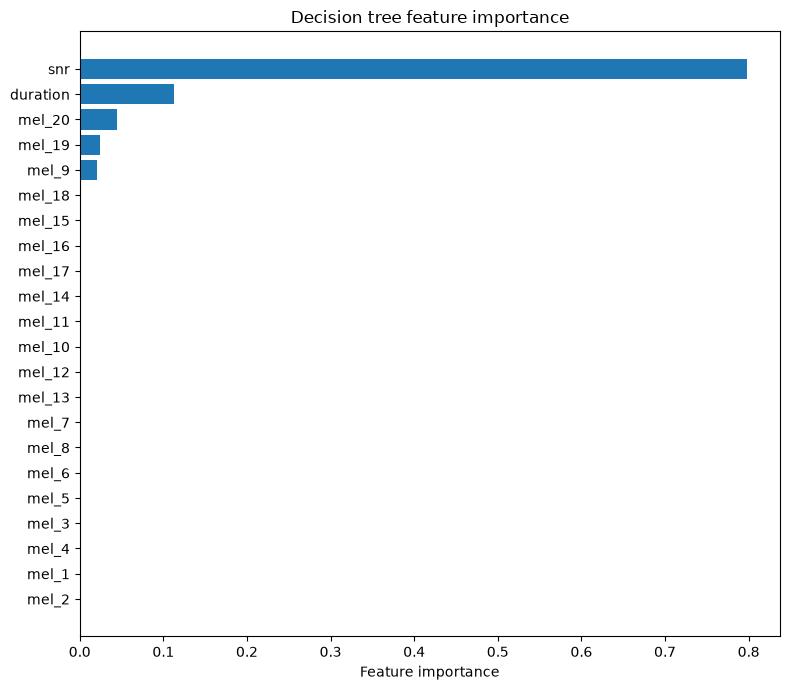

In [4]:
# Fit one final tree on all samples and save its feature-importance chart.
final_tree = make_tree()
final_tree.fit(X, y)
importance_order = np.argsort(final_tree.feature_importances_)
plt.figure(figsize=(8, 7))
plt.barh(np.arange(len(FEATURE_NAMES)), final_tree.feature_importances_[importance_order])
plt.yticks(np.arange(len(FEATURE_NAMES)), np.asarray(FEATURE_NAMES)[importance_order])
plt.xlabel("Feature importance")
plt.title("Decision tree feature importance")
plt.tight_layout()
figure_path = PROJECT_ROOT / "decision_tree_feature_importance.png"
plt.savefig(figure_path, dpi=150)
plt.show()


In [5]:
# ---- MLflow (Service 6) ----
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark")
mlflow.set_system_metrics_sampling_interval(1)
mlflow.enable_system_metrics_logging()

with mlflow.start_run(run_name="decision_tree", log_system_metrics=True) as run:
    mlflow.set_tags({
        "model": "DecisionTreeClassifier",
        "task": "pcg_normal_vs_abnormal",
        "evaluation": "3_fold_cross_validation",
        "feature_set": "duration_snr_20_mel_means",
    })
    mlflow.log_params({
        "max_depth": 3, "class_weight": "balanced", "random_state": 1,
        "n_folds": 3, "n_features": int(X.shape[1]), "n_samples": int(len(y)),
        "features": "duration + snr + 20 mel means",
    })
    for metric in ("accuracy", "precision", "recall", "f1"):
        mlflow.log_metric(f"mean_{metric}", float(results[metric].mean()))
    for row in fold_metrics:
        for metric in ("accuracy", "precision", "recall", "f1"):
            mlflow.log_metric(f"fold_{metric}", row[metric], step=row["fold"])
    mlflow.log_dict({"folds": fold_metrics}, "reports/cv_metrics.json")
    mlflow.log_dict({"folds": fold_confusions}, "reports/confusion_matrices.json")
    mlflow.log_dict({"feature_names": FEATURE_NAMES, "n_splits": 3, "shuffle": True, "random_state": 1}, "config/training_config.json")
    mlflow.log_artifact(str(figure_path), artifact_path="figures")
    mlflow.log_artifact(str(confusion_figure_path), artifact_path="figures")
    mlflow.sklearn.log_model(final_tree, name="decision_tree_model", serialization_format="cloudpickle", signature=infer_signature(X[:5], final_tree.predict(X[:5])), input_example=X[:5])
    print(f"Logged decision tree run: {run.info.run_id}")


2026/11/14 09:25:45 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/14 09:25:45 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/14 09:25:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/14 09:25:53 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/14 09:25:53 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


Logged decision tree run: a1550ba943f14761bc58dbff8e1768b2
🏃 View run decision_tree at: http://localhost:5000/#/experiments/1/runs/a1550ba943f14761bc58dbff8e1768b2
🧪 View experiment at: http://localhost:5000/#/experiments/1


## v2: patient-grouped 3-fold (Decision Tree)

Same protocol for every model (shared code in `audio_engine/evaluation/`):
1. **Folds**: loaded from `Data/processed/splits/v2_patient_grouped/fold_{1,2,3}.csv` (never regenerated here). A PASCAL patient (or PASCAL-A session, or PhysioNet recording) is never in two splits.
2. **Fit** on `train` only. Hyperparameter search (sklearn: inner grouped 3-fold CV inside `train`), early stopping (neural nets) and the **threshold** use `train`/`validation` only.
3. **Test** fold used once, for reporting. Metrics on train, validation and test with the same names for every model.

`RETRAIN = False` reloads the saved results of the last full run; set it to `True` to train again.

In [1]:
import sys
from pathlib import Path
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'audio_engine').is_dir())
sys.path.insert(0, str(root))
from IPython.display import Image, display
from audio_engine.evaluation.folds import load_folds, fold_report, manifest_sha
from audio_engine.evaluation.runners import load_or_run, fold_table
from audio_engine.evaluation.plots import train_vs_test, folds_overview
import pandas as pd

folds = load_folds()   # validates: no group shared between train/validation/test
print('split_manifest_sha =', manifest_sha())
pd.DataFrame(fold_report(folds))

split_manifest_sha = 53829bb5614daaffe5525acd4a1aad7dc622a66859ba90f98f9511428bf46b02


,fold,split,recordings,groups,pascal_patients,normal,abnormal,abnormal_share
0,1,train,2017,1849,85,542,1475,0.731
1,1,validation,507,459,25,136,371,0.732
2,1,test,1261,1147,55,338,923,0.732
3,2,train,2019,1854,89,542,1477,0.732
4,2,validation,504,449,20,135,369,0.732
5,2,test,1262,1152,56,339,923,0.731
6,3,train,2019,1849,91,542,1477,0.732
7,3,validation,504,450,20,135,369,0.732
8,3,test,1262,1156,54,339,923,0.731


In [2]:
RETRAIN = False
result = load_or_run('decision_tree', retrain=RETRAIN)
per_fold, mean_std = fold_table(result)
display(per_fold)
mean_std

,fold,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,roc_auc,specificity
0,1,train,0.344,0.863,0.846,0.927,0.883,0.904,0.832,0.929,0.810
1,1,validation,0.344,0.830,0.812,0.911,0.852,0.880,0.795,0.877,0.772
2,1,test,0.344,0.864,0.833,0.913,0.899,0.906,0.828,0.905,0.766
3,2,train,0.717,0.867,0.902,0.990,0.827,0.901,0.850,0.967,0.978
4,2,validation,0.717,0.784,0.801,0.928,0.764,0.838,0.756,0.826,0.837
5,2,test,0.717,0.807,0.827,0.943,0.784,0.856,0.782,0.869,0.870
6,3,train,0.840,0.878,0.915,0.998,0.834,0.909,0.861,0.979,0.996
7,3,validation,0.840,0.808,0.815,0.928,0.799,0.859,0.778,0.839,0.830
8,3,test,0.840,0.811,0.829,0.942,0.790,0.859,0.785,0.858,0.867


accuracy        balanced_accuracy        precision        recall  \
               mean    std              mean    std      mean    std   mean   
split                                                                         
test          0.827  0.032             0.830  0.003     0.933  0.017  0.824   
train         0.869  0.007             0.888  0.037     0.972  0.039  0.848   
validation    0.807  0.023             0.809  0.007     0.922  0.010  0.805   

                      f1        macro_f1        roc_auc        specificity  \
              std   mean    std     mean    std    mean    std        mean   
split                                                                        
test        0.065  0.874  0.028    0.799  0.026   0.877  0.024       0.835   
train       0.030  0.905  0.004    0.848  0.015   0.958  0.026       0.928   
validation  0.044  0.859  0.021    0.776  0.019   0.847  0.026       0.813   

                   
              std  
split              
test        0.059  
train       0.103  
validation  0.036

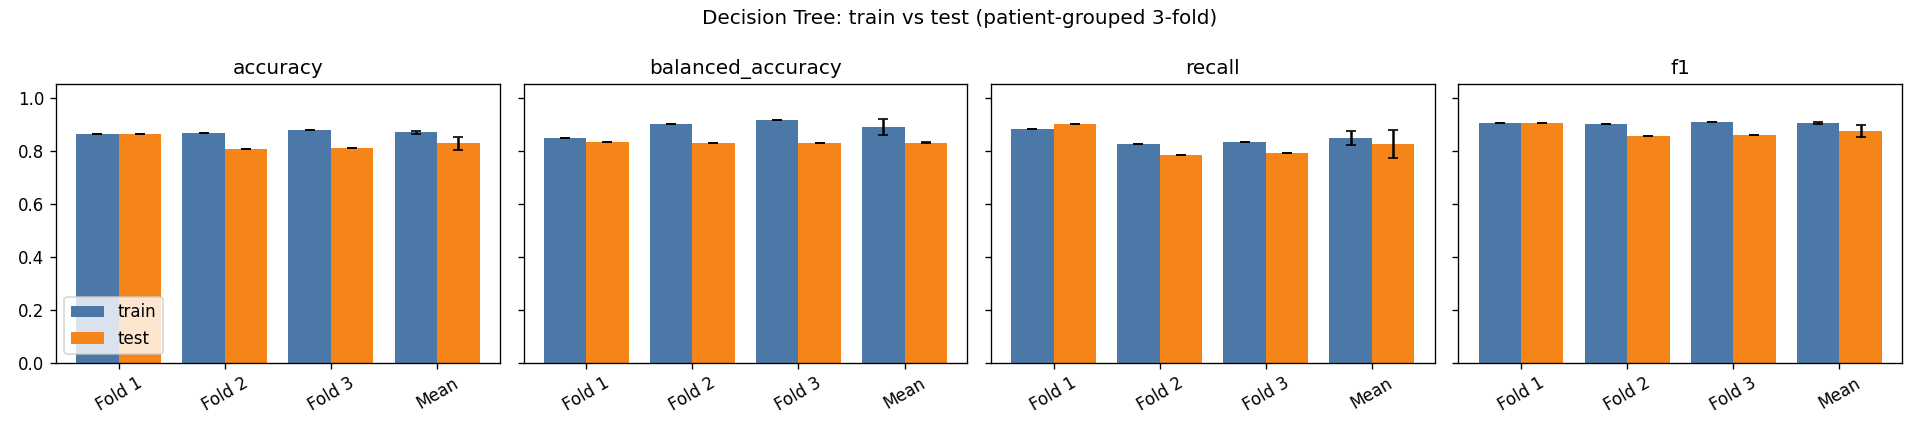

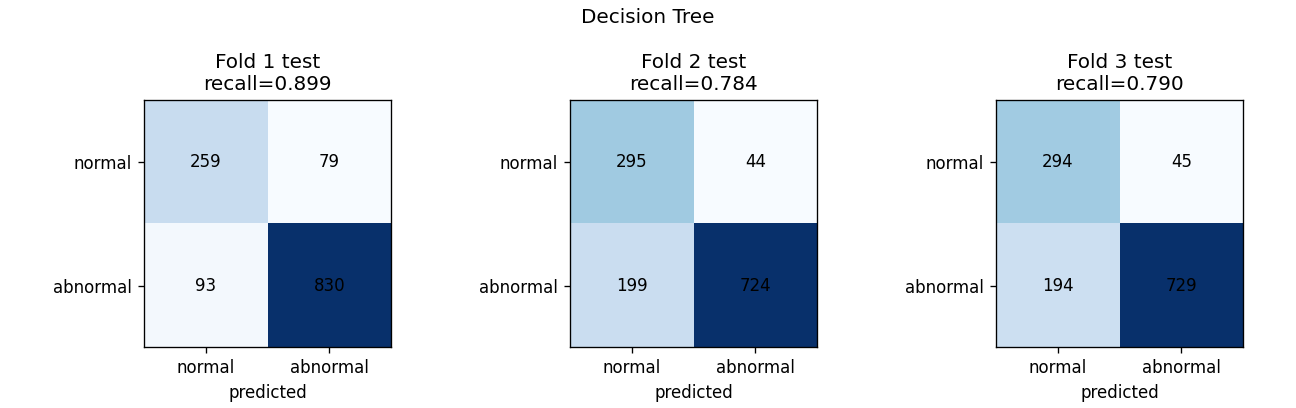

In [3]:
fig_dir = root / 'audio_engine' / 'evaluation' / 'figures' / 'decision_tree'
display(Image(str(train_vs_test(result['folds'], result['display_name'], fig_dir / 'train_vs_test.png'))))
display(Image(str(folds_overview(result['folds'], result['display_name'], fig_dir / 'folds_overview.png'))))